# 02 · Sentinel-2 over Antalya with STAC

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oechenique/remote_sensing/blob/main/notebooks/02_sentinel2_stac.ipynb)

Search Sentinel-2 Level-2A scenes through a **STAC API**, load only the pixels and bands needed with **odc-stac** (lazy, Cloud-Optimized GeoTIFFs read by window), mask clouds with the **Scene Classification Layer (SCL)** and compute **NDVI** with [`spyndex`](https://github.com/awesome-spectral-indices/spyndex).

Same area and month as the original 2024 notebook (Antalya, Turkey, December 2023), which plotted the first scene it found: it was 81 % clouds.

- **Catalog:** [Earth Search v1](https://earth-search.aws.element84.com/v1) by Element 84, no account or key needed.
- **Collection:** `sentinel-2-c1-l2a` (Sentinel-2 Collection 1): the whole archive since 2015 reprocessed with the 05.xx processing baselines, so scenes from different years are comparable.
- **Data:** Contains modified Copernicus Sentinel data 2023.

## Setup

In [1]:
# Colab already ships numpy, pandas, xarray, dask and matplotlib; install only what is missing.
# Locally, use requirements.txt instead.
import sys

if "google.colab" in sys.modules:
    %pip install -q rasterio==1.5.2 pystac-client==0.9.1 odc-stac==0.5.3 spyndex==0.12.0

In [2]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spyndex
from odc.stac import configure_rio, load
from pystac_client import Client

# pystac warns once per Earth Search asset it cannot map to a bucket; harmless for reading
warnings.filterwarnings("ignore", message="Could not parse bucket")
# rasterio's NotGeoreferencedWarning shows up intermittently while odc-stac reprojects;
# runs with and without it gave identical results
warnings.filterwarnings("ignore", category=UserWarning, module="rasterio.warp")
# GDAL settings for public cloud COGs (no directory listing, bigger reads)
configure_rio(cloud_defaults=True)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR = ROOT / "docs" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

## Search the catalog

In [3]:
EARTH_SEARCH = "https://earth-search.aws.element84.com/v1"
COLLECTION = "sentinel-2-c1-l2a"
BBOX = [30.444946, 36.804887, 30.933837, 37.059561]  # Antalya, same box as the 2024 notebook
MONTH = "2023-12"

catalog = Client.open(EARTH_SEARCH)
items = catalog.search(collections=[COLLECTION], bbox=BBOX, datetime=MONTH).item_collection()

scenes = (
    pd.DataFrame(
        {
            "date": i.datetime.date(),
            "tile": i.properties["grid:code"].removeprefix("MGRS-"),
            "cloud_cover_%": i.properties["eo:cloud_cover"],
        }
        for i in items
    )
    .sort_values(["date", "tile"])
    .reset_index(drop=True)
)
print(len(items), "scenes over", scenes.tile.nunique(), "MGRS tiles (the box straddles UTM zones 35 and 36),", scenes.date.nunique(), "acquisition days")
scenes.groupby("date").agg(tiles=("tile", "size"), mean_tile_cloud_cover_pct=("cloud_cover_%", "mean")).round(1)

60 scenes over 6 MGRS tiles (the box straddles UTM zones 35 and 36), 12 acquisition days


,tiles,mean_tile_cloud_cover_pct
date,,
2023-12-02,6,76.4
2023-12-05,4,17.8
2023-12-07,6,99.6
2023-12-10,4,61.0
2023-12-12,6,58.0
2023-12-15,4,99.0
2023-12-17,6,22.5
2023-12-20,4,0.7
2023-12-22,6,75.1


`eo:cloud_cover` is per **tile** (110 × 110 km), not per area of interest. A scene can be 80 % cloudy over the sea and clear over the city, or the other way round, so it is better to measure clouds on the pixels we actually load.

Digital numbers are converted to reflectance with the scale and offset published in each asset's `raster:bands` metadata (odc-stac does not apply them).

In [4]:
raster_band = items[0].assets["red"].extra_fields["raster:bands"][0]
SCALE, OFFSET = raster_band["scale"], raster_band["offset"]
print(f"reflectance = DN × {SCALE} + ({OFFSET})")

reflectance = DN × 0.0001 + (-0.1)


## Load lazily

Nothing is downloaded yet: `load` builds a dask-backed `xarray.Dataset` on a 20 m UTM grid, one time step per acquisition day (`groupby="solar_day"` merges the two tiles that cover the box).

In [5]:
BANDS = ["red", "green", "blue", "nir"]

ds = load(
    items,
    bands=BANDS + ["scl"],
    bbox=BBOX,
    crs="EPSG:32636",  # UTM 36N
    resolution=20,
    groupby="solar_day",
    chunks={"x": 2048, "y": 2048},
)
print(dict(ds.sizes), f"→ {ds.nbytes / 1e6:.0f} MB if fully loaded")

{'y': 1467, 'x': 2212, 'time': 12} → 350 MB if fully loaded


## Cloud masking with SCL

The L2A processor classifies every pixel. These classes are dropped: no data, saturated/defective, cloud shadow, medium and high probability clouds, and thin cirrus.

Class 2 (*dark area / topographic shadow*) is **kept** on purpose: in December the sun is low and the north-facing slopes of the Taurus Mountains are in shadow on every single day. Dropping it leaves permanent holes in the composite.

In [6]:
SCL_DROP = {0: "no data", 1: "saturated", 3: "cloud shadow", 8: "cloud (medium)", 9: "cloud (high)", 10: "thin cirrus"}

clear = ~ds.scl.isin(list(SCL_DROP))
clear_share = (clear & (ds.scl > 0)).sum(["x", "y"]) / (ds.scl > 0).sum(["x", "y"])
clear_share = clear_share.compute().to_series()
clear_share.index = clear_share.index.date
clear_share.rename("clear pixels in the box").to_frame().style.format("{:.0%}")

,clear pixels in the box
2023-12-02,31%
2023-12-05,71%
2023-12-07,0%
2023-12-10,8%
2023-12-12,17%
2023-12-15,0%
2023-12-17,100%
2023-12-20,100%
2023-12-22,16%
2023-12-25,100%


In [7]:
def to_reflectance(ds, bands, valid):
    """DN → surface reflectance, keeping only valid (clear, non-empty) pixels."""
    dn = ds[bands]
    refl = dn.where(valid & (dn > 0)) * SCALE + OFFSET
    # The -0.1 offset can push very dark pixels (deep shadow, water) slightly below zero
    return refl.clip(min=0)


def rgb(d, vmax=0.25):
    """True-colour image with a simple linear stretch."""
    return np.clip(np.dstack([d.red.values, d.green.values, d.blue.values]) / vmax, 0, 1)


first_day = ds.time.values[0]  # the 2024 notebook plotted ds.isel(time=0): the first day of the month
first = to_reflectance(ds.sel(time=first_day), BANDS, ds.scl.sel(time=first_day) > 0).compute()
composite = to_reflectance(ds, BANDS, clear).median("time").compute()
print("first scene:", pd.Timestamp(first_day).date(), f"· clear pixels: {clear_share.iloc[0]:.0%}")
print(f"monthly composite: {composite.red.notnull().mean().item():.1%} of pixels have a clear value")

first scene: 2023-12-02 · clear pixels: 31%
monthly composite: 100.0% of pixels have a clear value


## NDVI

$NDVI = \frac{NIR - Red}{NIR + Red}$, taken from the [Awesome Spectral Indices](https://github.com/awesome-spectral-indices/awesome-spectral-indices) catalog via `spyndex` so the formula is never typed by hand.

In [8]:
print(spyndex.indices.NDVI.long_name, "·", spyndex.indices.NDVI.formula)
ndvi = spyndex.computeIndex("NDVI", params={"N": composite.nir, "R": composite.red})
print(f"median NDVI on land (NDVI > 0): {ndvi.where(ndvi > 0).median().item():.2f}")

Normalized Difference Vegetation Index · (N-R)/(N+R)
median NDVI on land (NDVI > 0): 0.48


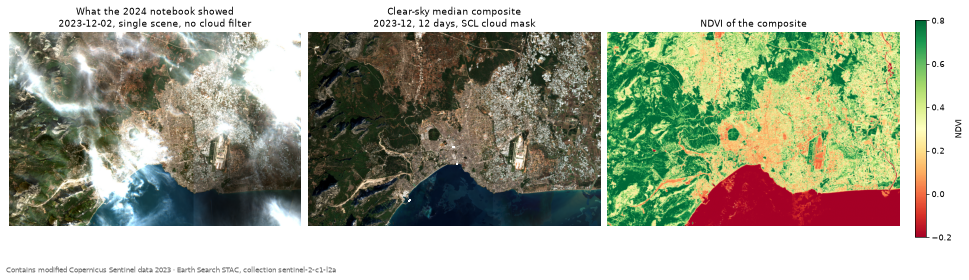

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)

axes[0].imshow(rgb(first))
axes[0].set_title(f"What the 2024 notebook showed\n{pd.Timestamp(first_day).date()}, single scene, no cloud filter", fontsize=11)

axes[1].imshow(rgb(composite))
axes[1].set_title(f"Clear-sky median composite\n{MONTH}, {ds.sizes['time']} days, SCL cloud mask", fontsize=11)

im = axes[2].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
axes[2].set_title("NDVI of the composite", fontsize=11)
fig.colorbar(im, ax=axes[2], shrink=0.8, label="NDVI")

for ax in axes:
    ax.set_axis_off()
fig.text(0.0, -0.02, "Contains modified Copernicus Sentinel data 2023 · Earth Search STAC, collection sentinel-2-c1-l2a", fontsize=8, color="0.4")
# JPEG: satellite imagery is photographic, a PNG of it is ~5x larger
fig.savefig(IMG_DIR / "antalya_stac.jpg", dpi=130, bbox_inches="tight", pil_kwargs={"quality": 88})
fig.set_dpi(60)  # full resolution goes to docs/img; keep the notebook light
plt.show()

## What changed from the 2024 version

- `sentinel-2-l2a` → **`sentinel-2-c1-l2a`**: the older collection mixes processing baselines (02.xx to 05.xx) and its `raster:bands` offset does not match its pixels (see notebook 03); Collection 1 is one consistent reprocessing.
- Clouds are measured and masked per pixel with **SCL**, and a monthly **median composite** replaces "the first scene returned".
- DN → reflectance with the published scale and offset; **true-colour RGB** instead of three separate single-band plots.
- **NDVI** via `spyndex`.

Next: [`03_manavgat_burn_ndvi.ipynb`](03_manavgat_burn_ndvi.ipynb) uses the same tools 60 km east, on the 2021 Manavgat wildfire.